In [5]:
#1
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)

OpenCV: 5.0.0
NumPy: 2.4.6


#2
# Lane Detection Baseline

This notebook implements a classical computer-vision baseline for lane detection.

Pipeline:
1. Image acquisition
2. Grayscale conversion
3. Gaussian blur
4. Canny edge detection
5. Region of interest (ROI)
6. Lane-line detection
7. Lane-centre estimation
8. 

Image loaded successfully
Image shape: (3781, 3024, 3)


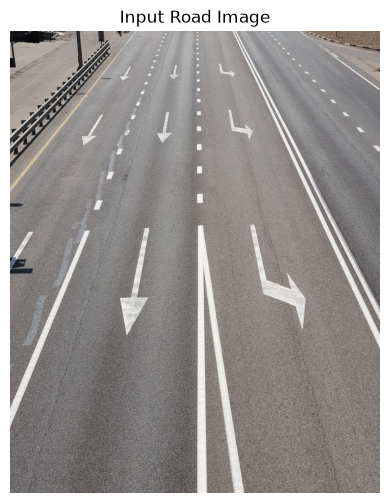

In [6]:
#3
from pathlib import Path

image_path = Path("../../datasets/lane_detection/road_01.jpg")

image = cv2.imread(str(image_path))

if image is None:
    raise FileNotFoundError(f"Could not load image: {image_path}")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

print("Image loaded successfully")
print("Image shape:", image.shape)

plt.figure(figsize=(10, 6))
plt.imshow(image_rgb)
plt.axis("off")
plt.title("Input Road Image")
plt.show()

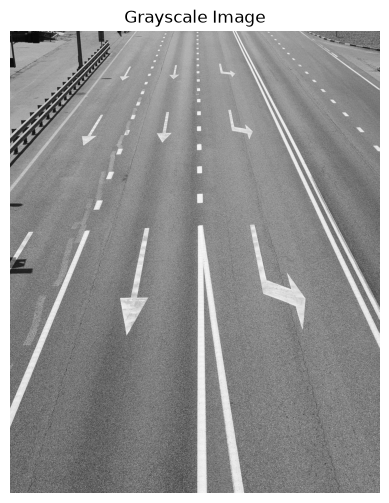

In [7]:
#4
#  Convert the RGB image to grayscale.
# Grayscale keeps intensity information while removing color information.
gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)

# Display the grayscale image.
plt.figure(figsize=(10, 6))
plt.imshow(gray, cmap="gray")
plt.axis("off")
plt.title("Grayscale Image")
plt.show()

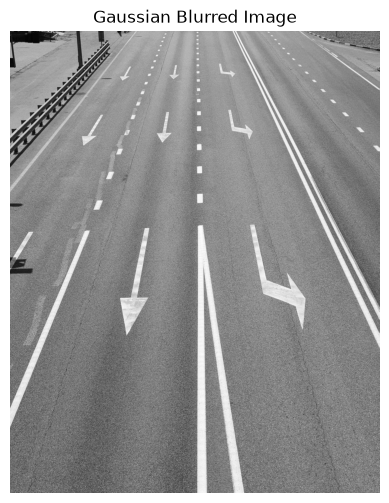

In [8]:
#5
#  Apply Gaussian blur to reduce image noise and small surface details.
# This helps Canny edge detection focus on stronger, meaningful edges.
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# Display the blurred image.
plt.figure(figsize=(10, 6))
plt.imshow(blurred, cmap="gray")
plt.axis("off")
plt.title("Gaussian Blurred Image")
plt.show()

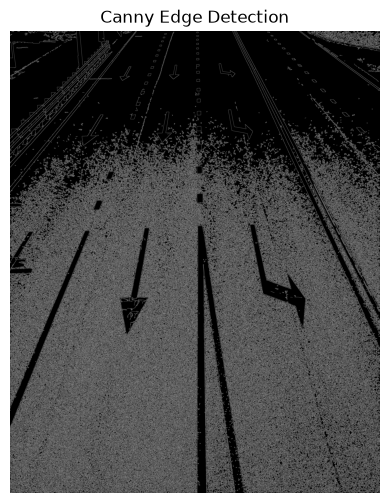

Unique edge values: [  0 255]
Edge image shape: (3781, 3024)
Edge image data type: uint8


In [9]:
#6
#  Detect strong intensity changes that may correspond to lane boundaries.
edges = cv2.Canny(blurred, 50, 150)

# Display the detected edges.
plt.figure(figsize=(10, 6))
plt.imshow(edges, cmap="gray")
plt.axis("off")
plt.title("Canny Edge Detection")
plt.show()
# Check the pixel values produced by Canny edge detection.
# A normal Canny result should contain only 0 and 255.
print("Unique edge values:", np.unique(edges))
print("Edge image shape:", edges.shape)
print("Edge image data type:", edges.dtype)

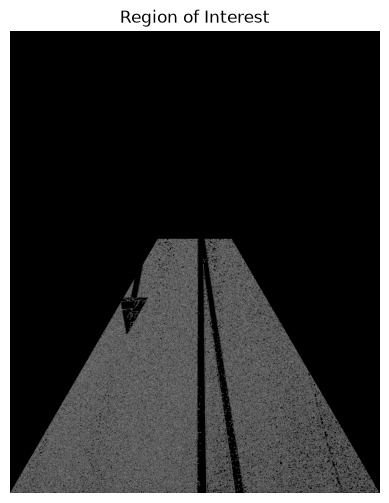

In [10]:
# 7
# Define a polygon covering the road area relevant for lane detection.
# Everything outside this region will be ignored.
height, width = edges.shape

roi_vertices = np.array([[
    (0, height),
    (width, height),
    (int(width * 0.60), int(height * 0.45)),
    (int(width * 0.40), int(height * 0.45))
]], dtype=np.int32)

# Create a black mask and fill the ROI with white.
mask = np.zeros_like(edges)
cv2.fillPoly(mask, roi_vertices, 255)

# Keep only the edges inside the ROI.
roi_edges = cv2.bitwise_and(edges, mask)

# Display the selected region and its remaining edges.
plt.figure(figsize=(10, 6))
plt.imshow(roi_edges, cmap="gray")
plt.axis("off")
plt.title("Region of Interest")
plt.show()

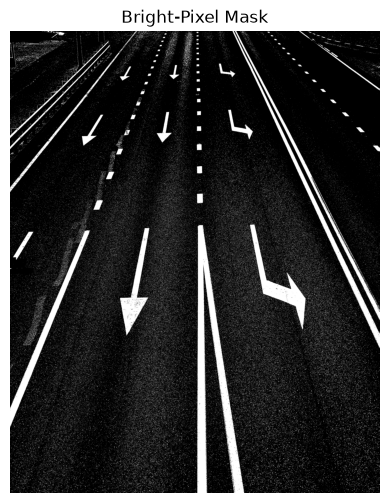

In [11]:
# 8
# Detect bright pixels that are likely to belong to white lane markings.
# This shows which image regions are bright before combining them with Canny edges.
white_mask = cv2.inRange(gray, 180, 255)

# Display the detected bright regions.
plt.figure(figsize=(10, 6))
plt.imshow(white_mask, cmap="gray")
plt.axis("off")
plt.title("Bright-Pixel Mask")
plt.show()

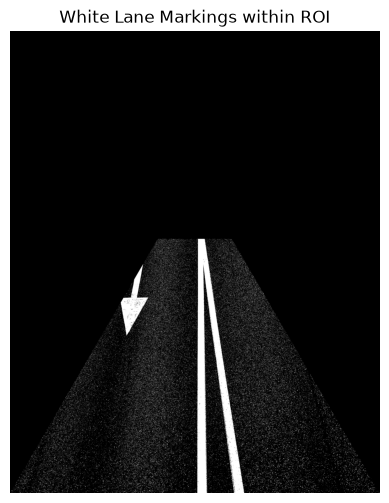

In [12]:
# 9
# Restrict the bright-pixel mask to the road ROI.
# This removes bright objects outside the region relevant to lane detection.
roi_white_mask = cv2.bitwise_and(
    white_mask,
    mask
)

# Display the bright pixels that remain inside the road ROI.
plt.figure(figsize=(10, 6))
plt.imshow(roi_white_mask, cmap="gray")
plt.axis("off")
plt.title("White Lane Markings within ROI")
plt.show()

Detected line segments: 8238


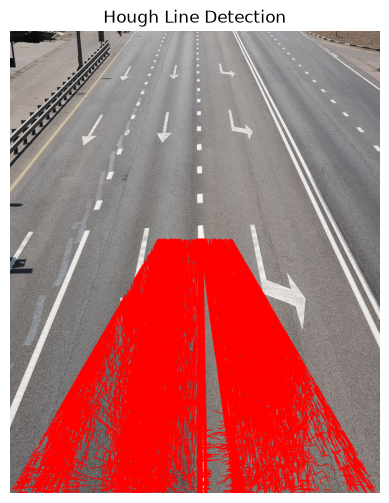

In [13]:
# 10
# Detect straight line segments from the lane-marking candidates.
# HoughLinesP identifies groups of aligned pixels and returns
# the start and end coordinates of each detected line.
lines = cv2.HoughLinesP(
    roi_white_mask,
    rho=1,
    theta=np.pi / 180,
    threshold=50,
    minLineLength=50,
    maxLineGap=30
)

# Create a copy of the original image so the detected lines
# can be drawn without modifying the original image.
line_image = image_rgb.copy()

if lines is not None:

    # HoughLinesP may return an array with shape (N, 1, 4).
    # Reshape it so each detected segment is represented directly as:
    # [x1, y1, x2, y2].
    lines = lines.reshape(-1, 4)

    # Draw every detected line segment.
    for x1, y1, x2, y2 in lines:

        cv2.line(
            line_image,
            (x1, y1),
            (x2, y2),
            (255, 0, 0),
            5
        )

    print(f"Detected line segments: {len(lines)}")

else:
    print("No line segments detected.")

# Display the detected line segments on the original image.
plt.figure(figsize=(10, 6))
plt.imshow(line_image)
plt.axis("off")
plt.title("Hough Line Detection")
plt.show()

In [14]:
# 11
# Filter Hough line segments based on their orientation and position.
# Lane boundaries in this image are expected to be long, diagonal lines
# that converge toward the upper-middle part of the road.

# Make sure each Hough segment is represented as [x1, y1, x2, y2].
line_segments = lines.reshape(-1, 4)

left_lines = []
right_lines = []

height, width = edges.shape

for x1, y1, x2, y2 in line_segments:

    # Reorder the endpoints so that (x1, y1) is the lower point
    # and (x2, y2) is the upper point in the image.
    if y1 < y2:
        x1, x2 = x2, x1
        y1, y2 = y2, y1

    # Ignore almost-horizontal segments because lane boundaries
    # should have a noticeable diagonal orientation.
    if abs(x2 - x1) < 20:
        continue

    # Calculate the line slope in image coordinates.
    slope = (y2 - y1) / (x2 - x1)

    # Ignore segments that are too close to horizontal.
    if abs(slope) < 0.3:
        continue

    # Use the lower endpoint to determine whether the segment
    # belongs to the left or right side of the lane.
    if x1 < width * 0.5 and slope < 0:
        left_lines.append((x1, y1, x2, y2))

    elif x1 > width * 0.5 and slope > 0:
        right_lines.append((x1, y1, x2, y2))

print(f"Filtered left-line segments: {len(left_lines)}")
print(f"Filtered right-line segments: {len(right_lines)}")

Filtered left-line segments: 1793
Filtered right-line segments: 2216


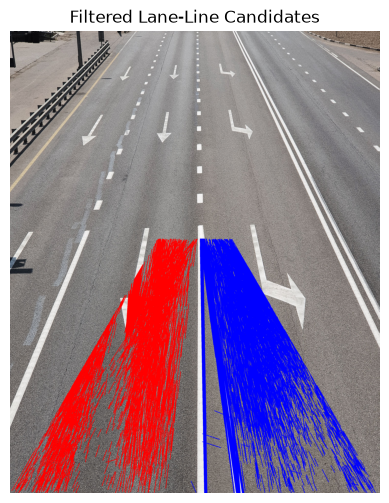

In [15]:
# 12
# Draw the filtered left and right lane candidates on the original image.
filtered_image = image_rgb.copy()

# Draw left-lane candidates in red.
for x1, y1, x2, y2 in left_lines:
    cv2.line(
        filtered_image,
        (x1, y1),
        (x2, y2),
        (255, 0, 0),
        3
    )

# Draw right-lane candidates in blue.
for x1, y1, x2, y2 in right_lines:
    cv2.line(
        filtered_image,
        (x1, y1),
        (x2, y2),
        (0, 0, 255),
        3
    )

# Display the filtered candidate lines.
plt.figure(figsize=(10, 6))
plt.imshow(filtered_image)
plt.axis("off")
plt.title("Filtered Lane-Line Candidates")
plt.show()

In [16]:
# 13
# Estimate one representative line for each lane
# by combining the filtered candidate segments.

def estimate_lane_line(line_segments):
    """
    Estimate a single lane boundary from multiple line segments.

    Each segment contributes its endpoints to a linear fit.
    The result is returned as (slope, intercept).
    """

    if not line_segments:
        return None

    # Collect all endpoints from the detected segments.
    points = []

    for x1, y1, x2, y2 in line_segments:
        points.append((x1, y1))
        points.append((x2, y2))

    points = np.array(points)

    # Fit a straight line:
    # y = slope * x + intercept
    slope, intercept = np.polyfit(
        points[:, 0],
        points[:, 1],
        1
    )

    return slope, intercept


# Estimate the left and right lane boundaries.
left_lane = estimate_lane_line(left_lines)
right_lane = estimate_lane_line(right_lines)

print("Estimated left lane:", left_lane)
print("Estimated right lane:", right_lane)

Estimated left lane: (np.float64(-1.1311375428252908), np.float64(3818.158332750454))
Estimated right lane: (np.float64(1.2486664319875593), np.float64(92.55699930352394))


In [17]:
# 14
# Refine the lane candidates before fitting the final lane boundaries.
# The expected lane boundaries should remain on their respective sides
# of the image at both the bottom and top of the ROI.

height, width = edges.shape

y_bottom = height
y_top = int(height * 0.45)


def filter_lane_candidates(line_segments, side):
    """
    Keep line segments whose projected positions are consistent
    with the expected left or right lane boundary.
    """

    filtered = []

    for x1, y1, x2, y2 in line_segments:

        # Calculate the slope of the line segment.
        dx = x2 - x1
        dy = y2 - y1

        if abs(dx) < 20:
            continue

        slope = dy / dx

        # Project the segment to the bottom and top of the ROI.
        intercept = y1 - slope * x1

        x_bottom = (y_bottom - intercept) / slope
        x_top = (y_top - intercept) / slope

        # Keep only lines with the expected orientation and position.
        if side == "left":
            if (
                slope < -0.5
                and width * 0.15 < x_bottom < width * 0.48
                and width * 0.35 < x_top < width * 0.55
            ):
                filtered.append((x1, y1, x2, y2))

        elif side == "right":
            if (
                slope > 0.5
                and width * 0.52 < x_bottom < width * 0.85
                and width * 0.35 < x_top < width * 0.65
            ):
                filtered.append((x1, y1, x2, y2))

    return filtered


# Apply the position and orientation filters.
refined_left_lines = filter_lane_candidates(
    left_lines,
    "left"
)

refined_right_lines = filter_lane_candidates(
    right_lines,
    "right"
)


print(
    f"Refined left-line segments: "
    f"{len(refined_left_lines)}"
)

print(
    f"Refined right-line segments: "
    f"{len(refined_right_lines)}"
)

Refined left-line segments: 952
Refined right-line segments: 1228


Visualized refined left candidates: 952
Visualized refined right candidates: 1228


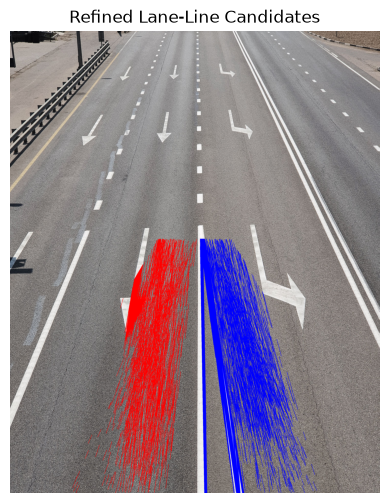

In [18]:
# 15
#  Visualize the refined Hough-line candidates.
# Red = refined left-lane candidates
# Blue = refined right-lane candidates

refined_visualization = image_rgb.copy()

# Draw all refined left-lane segments in red.
for x1, y1, x2, y2 in refined_left_lines:
    cv2.line(
        refined_visualization,
        (x1, y1),
        (x2, y2),
        (255, 0, 0),
        2
    )

# Draw all refined right-lane segments in blue.
for x1, y1, x2, y2 in refined_right_lines:
    cv2.line(
        refined_visualization,
        (x1, y1),
        (x2, y2),
        (0, 0, 255),
        2
    )

print(f"Visualized refined left candidates: {len(refined_left_lines)}")
print(f"Visualized refined right candidates: {len(refined_right_lines)}")

plt.figure(figsize=(10, 6))
plt.imshow(refined_visualization)
plt.axis("off")
plt.title("Refined Lane-Line Candidates")
plt.show()

In [19]:
# 16
#  Fit one representative line to the refined candidate segments.
# Longer segments are given more influence because they generally
# provide stronger geometric evidence.

def estimate_lane_line_weighted(line_segments):

    if not line_segments:
        return None

    points = []
    weights = []

    for x1, y1, x2, y2 in line_segments:

        # Add both endpoints of the line segment.
        points.append((x1, y1))
        points.append((x2, y2))

        # Calculate the segment length.
        length = np.hypot(
            x2 - x1,
            y2 - y1
        )

        # Give both endpoints the same weight.
        weights.extend([length, length])

    points = np.array(points)
    weights = np.array(weights)

    # Fit y = slope*x + intercept.
    slope, intercept = np.polyfit(
        points[:, 0],
        points[:, 1],
        1,
        w=weights
    )

    return slope, intercept


# Estimate the refined lane boundaries.
left_lane = estimate_lane_line_weighted(
    refined_left_lines
)

right_lane = estimate_lane_line_weighted(
    refined_right_lines
)


print("Refined left lane:", left_lane)
print("Refined right lane:", right_lane)

Refined left lane: (np.float64(-1.7513721579150539), np.float64(4576.737463440319))
Refined right lane: (np.float64(2.4917889751952336), np.float64(-1611.9276134172067))


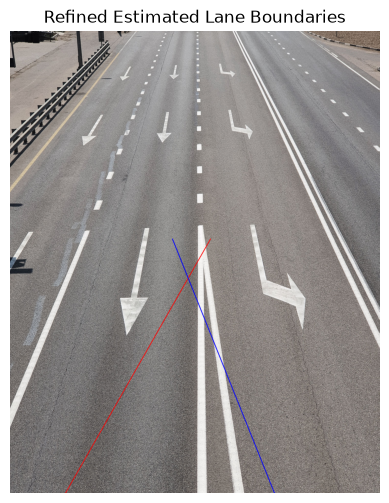

In [20]:
# 17
# Draw the refined estimated lane boundaries.

lane_image = image_rgb.copy()


def draw_lane_line(image, line, y_bottom, y_top, color):

    if line is None:
        return

    slope, intercept = line

    # Calculate x coordinates from y = slope*x + intercept.
    x_bottom = int(
        (y_bottom - intercept) / slope
    )

    x_top = int(
        (y_top - intercept) / slope
    )

    cv2.line(
        image,
        (x_bottom, y_bottom),
        (x_top, y_top),
        color,
        6
    )


# Draw the left and right lane boundaries.
draw_lane_line(
    lane_image,
    left_lane,
    y_bottom,
    y_top,
    (255, 0, 0)
)

draw_lane_line(
    lane_image,
    right_lane,
    y_bottom,
    y_top,
    (0, 0, 255)
)


# Display the result.
plt.figure(figsize=(10, 6))
plt.imshow(lane_image)
plt.axis("off")
plt.title("Refined Estimated Lane Boundaries")
plt.show()

In [21]:
# 18
# Apply stricter geometric constraints to the lane candidates.
# The purpose is to reject Hough segments that do not pass through
# the expected left/right lane-boundary regions.

height, width = edges.shape

y_bottom = height
y_top = int(height * 0.45)


def filter_lane_candidates_strict(line_segments, side):
    """
    Keep candidate segments whose extrapolated positions are
    consistent with the expected lane boundaries.
    """

    filtered = []

    for x1, y1, x2, y2 in line_segments:

        dx = x2 - x1
        dy = y2 - y1

        # Ignore almost-vertical segments because they provide
        # little information for the current lane geometry.
        if abs(dx) < 20:
            continue

        slope = dy / dx

        # Calculate the line intercept:
        # y = slope*x + intercept
        intercept = y1 - slope * x1

        # Calculate where this candidate would intersect
        # the bottom and top of the selected ROI.
        x_bottom = (y_bottom - intercept) / slope
        x_top = (y_top - intercept) / slope

        if side == "left":

            # The left lane boundary should:
            # - slope upward toward the vanishing point
            # - remain on the left side at the bottom
            # - approach the image centre near the top
            if (
                -3.0 < slope < -0.7
                and width * 0.20 < x_bottom < width * 0.45
                and width * 0.40 < x_top < width * 0.58
            ):
                filtered.append((x1, y1, x2, y2))

        elif side == "right":

            # The right lane boundary should:
            # - slope upward toward the vanishing point
            # - remain on the right side at the bottom
            # - approach the image centre near the top
            if (
                0.7 < slope < 3.0
                and width * 0.55 < x_bottom < width * 0.80
                and width * 0.40 < x_top < width * 0.60
            ):
                filtered.append((x1, y1, x2, y2))

    return filtered


# Apply the stricter filtering.
strict_left_lines = filter_lane_candidates_strict(
    refined_left_lines,
    "left"
)

strict_right_lines = filter_lane_candidates_strict(
    refined_right_lines,
    "right"
)


print(
    f"Strict left-line segments: "
    f"{len(strict_left_lines)}"
)

print(
    f"Strict right-line segments: "
    f"{len(strict_right_lines)}"
)

Strict left-line segments: 102
Strict right-line segments: 80


In [22]:
# 19
# Estimate one representative lane boundary from the strictly
# filtered Hough segments.
#
# For each candidate line, calculate where it intersects the
# top and bottom of the ROI. The median positions are then used
# to obtain a robust representative lane boundary.


def estimate_lane_line_robust(line_segments, y_bottom, y_top):

    if not line_segments:
        return None

    bottom_positions = []
    top_positions = []

    for x1, y1, x2, y2 in line_segments:

        dx = x2 - x1
        dy = y2 - y1

        # Avoid unstable slope calculations for nearly vertical lines.
        if abs(dx) < 20:
            continue

        # Represent the segment as:
        # y = slope*x + intercept
        slope = dy / dx
        intercept = y1 - slope * x1

        # Find the x-position of the candidate line at the
        # bottom and top of the ROI.
        x_bottom = (y_bottom - intercept) / slope
        x_top = (y_top - intercept) / slope

        bottom_positions.append(x_bottom)
        top_positions.append(x_top)

    if not bottom_positions:
        return None

    # The median reduces the influence of remaining outliers.
    x_bottom = np.median(bottom_positions)
    x_top = np.median(top_positions)

    # Convert the two representative points back into:
    # y = slope*x + intercept
    slope = (y_bottom - y_top) / (x_bottom - x_top)
    intercept = y_bottom - slope * x_bottom

    return slope, intercept


# Estimate the final left and right lane boundaries.
left_lane = estimate_lane_line_robust(
    strict_left_lines,
    y_bottom,
    y_top
)

right_lane = estimate_lane_line_robust(
    strict_right_lines,
    y_bottom,
    y_top
)


print("Final left lane:", left_lane)
print("Final right lane:", right_lane)

Final left lane: (np.float64(-2.6338472954780197), np.float64(5639.612388514999))
Final right lane: (np.float64(2.821993553122395), np.float64(-2919.027402995157))


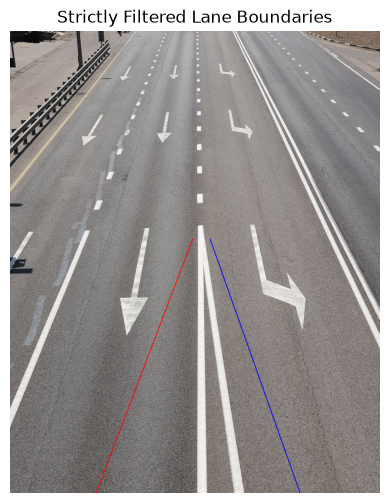

In [23]:
# 20
# Display the lane boundaries obtained after strict filtering.

lane_image = image_rgb.copy()

draw_lane_line(
    lane_image,
    left_lane,
    y_bottom,
    y_top,
    (255, 0, 0)
)

draw_lane_line(
    lane_image,
    right_lane,
    y_bottom,
    y_top,
    (0, 0, 255)
)

plt.figure(figsize=(10, 6))
plt.imshow(lane_image)
plt.axis("off")
plt.title("Strictly Filtered Lane Boundaries")
plt.show()

In [24]:
# 21
# Estimate the lane centre at a selected position in the image.
# The lane boundaries are represented as:
# y = slope * x + intercept

height, width = image.shape[:2]

# Select a horizontal position near the bottom of the image.
# This represents the road position closest to the vehicle.
y_eval = int(height * 0.90)

# Extract slope and intercept for the final left and right lanes.
left_slope, left_intercept = left_lane
right_slope, right_intercept = right_lane

# Convert the line equation y = mx + b into:
# x = (y - b) / m
left_x = (y_eval - left_intercept) / left_slope
right_x = (y_eval - right_intercept) / right_slope

# Calculate the midpoint between the two lane boundaries.
lane_center_x = (left_x + right_x) / 2

# Calculate the horizontal centre of the camera image.
image_center_x = width / 2

# Positive offset means the detected lane centre is to the right
# of the image centre; negative means it is to the left.
lateral_offset = lane_center_x - image_center_x

print(f"Evaluation y-position: {y_eval}")
print(f"Left lane x-position: {left_x:.1f}")
print(f"Right lane x-position: {right_x:.1f}")
print(f"Lane centre x-position: {lane_center_x:.1f}")
print(f"Image centre x-position: {image_center_x:.1f}")
print(f"Lateral offset: {lateral_offset:.1f} pixels")

Evaluation y-position: 3402
Left lane x-position: 849.6
Right lane x-position: 2239.9
Lane centre x-position: 1544.7
Image centre x-position: 1512.0
Lateral offset: 32.7 pixels


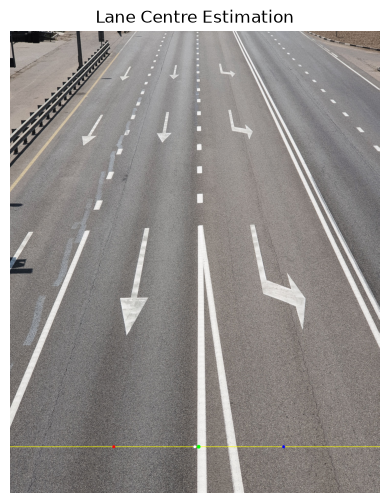

In [25]:
# 22
# Visualize the estimated lane centre and image centre.

visualization = image_rgb.copy()

# Draw the selected evaluation line.
cv2.line(
    visualization,
    (0, y_eval),
    (width, y_eval),
    (255, 255, 0),
    3
)

# Mark the left and right lane positions.
cv2.circle(
    visualization,
    (int(left_x), y_eval),
    12,
    (255, 0, 0),
    -1
)

cv2.circle(
    visualization,
    (int(right_x), y_eval),
    12,
    (0, 0, 255),
    -1
)

# Mark the estimated lane centre.
cv2.circle(
    visualization,
    (int(lane_center_x), y_eval),
    15,
    (0, 255, 0),
    -1
)

# Mark the centre of the image.
cv2.circle(
    visualization,
    (int(image_center_x), y_eval),
    12,
    (255, 255, 255),
    -1
)

plt.figure(figsize=(10, 6))
plt.imshow(visualization)
plt.axis("off")
plt.title("Lane Centre Estimation")
plt.show()

In [26]:
# 23
# Normalize the lateral offset for use as a control input.
# Positive values indicate that the estimated lane centre
# lies to the right of the image centre.

normalized_lateral_error = lateral_offset / image_center_x

print(f"Normalized lateral error: {normalized_lateral_error:.4f}")

Normalized lateral error: 0.0217


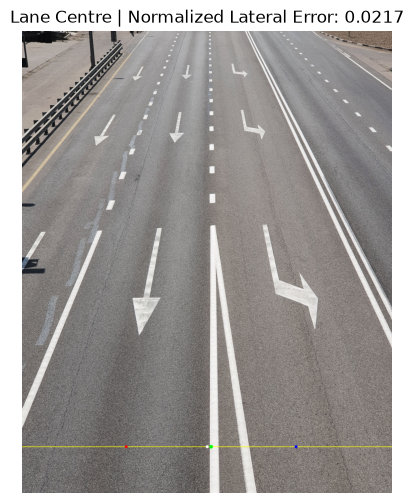

In [27]:
# 24
# Display the final perception result and steering error.

plt.figure(figsize=(10, 6))
plt.imshow(visualization)
plt.axis("off")
plt.title(
    f"Lane Centre | Normalized Lateral Error: "
    f"{normalized_lateral_error:.4f}"
)
plt.show()

In [28]:
#25
from pathlib import Path

# Find all validation images in the lane-detection dataset folder.
image_paths = sorted(
    Path("../../datasets/lane_detection").glob("road_*.jpg")
)

print("Validation images:")
for path in image_paths:
    print("-", path)

print(f"\nNumber of validation images: {len(image_paths)}")

Validation images:
- ..\..\datasets\lane_detection\road_01.jpg
- ..\..\datasets\lane_detection\road_02.jpg
- ..\..\datasets\lane_detection\road_03.jpg

Number of validation images: 3


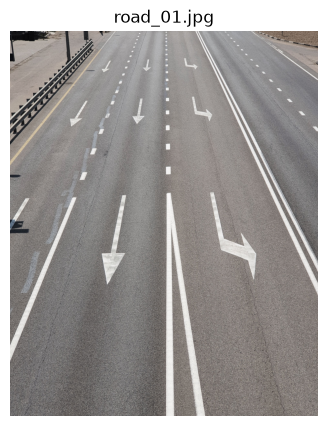

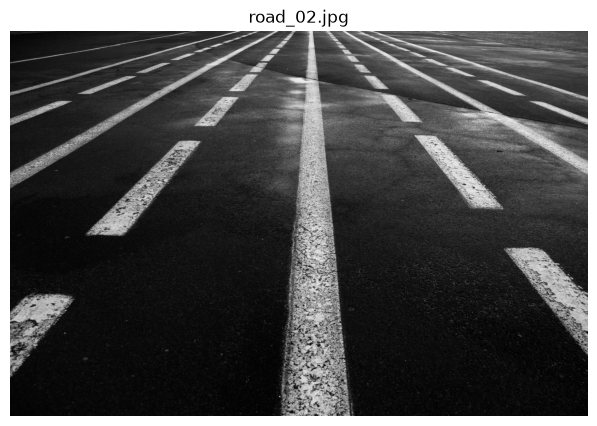

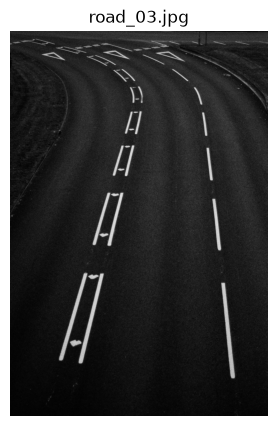

In [ ]:
#26
# Display all validation images before running the detection pipeline.
# This allows us to visually check the validation set.

for image_path in image_paths:
    image = cv2.imread(str(image_path))

    if image is None:
        print(f"Could not load: {image_path}")
        continue

    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 5))
    plt.imshow(image_rgb)
    plt.axis("off")
    plt.title(image_path.name)
    plt.show()

In [40]:
# 27
def run_lane_detection(image_path):
    """
    Run the current classical lane-detection pipeline
    on one input image.

    Returns the detected lane boundaries,
    lane centre, and normalized lateral error.
    """

    # Load image.
    image = cv2.imread(str(image_path))

    if image is None:
        raise FileNotFoundError(
            f"Could not load image: {image_path}"
        )

    image_rgb = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    # Image dimensions.
    height, width = image.shape[:2]

    # ---------------------------------------------------------
    # 1. Grayscale conversion
    # ---------------------------------------------------------

    gray = cv2.cvtColor(
        image_rgb,
        cv2.COLOR_RGB2GRAY
    )

    # ---------------------------------------------------------
    # 2. Gaussian blur
    # ---------------------------------------------------------

    blurred = cv2.GaussianBlur(
        gray,
        (5, 5),
        0
    )

    # ---------------------------------------------------------
    # 3. Canny edge detection
    # ---------------------------------------------------------

    edges = cv2.Canny(
        blurred,
        50,
        150
    )

    # ---------------------------------------------------------
    # 4. Region of interest
    # ---------------------------------------------------------

    roi_vertices = np.array([
        (0, height),
        (width, height),
        (int(width * 0.60), int(height * 0.45)),
        (int(width * 0.40), int(height * 0.45))
    ], dtype=np.int32)

    mask = np.zeros_like(edges)

    cv2.fillPoly(
        mask,
        [roi_vertices],
        255
    )

    roi_edges = cv2.bitwise_and(
        edges,
        mask
    )

    # ---------------------------------------------------------
    # 5. Bright-pixel filtering
    # ---------------------------------------------------------

    white_mask = cv2.inRange(
        gray,
        180,
        255
    )

    roi_white_mask = cv2.bitwise_and(
        white_mask,
        mask
    )

    lane_edges = cv2.bitwise_and(
        roi_edges,
        white_mask
    )

    # ---------------------------------------------------------
    # 6. Hough line detection
    # ---------------------------------------------------------

    lines = cv2.HoughLinesP(
        roi_white_mask,
        rho=1,
        theta=np.pi / 180,
        threshold=50,
        minLineLength=50,
        maxLineGap=30
    )

    # ---------------------------------------------------------
    # 7. Separate left and right candidates
    # ---------------------------------------------------------

    left_lines = []
    right_lines = []

    if lines is not None:

        for line in lines:

            x1, y1, x2, y2 = line

            # Reorder the endpoints so that (x1, y1)
            # is always the lower point in the image.
            if y1 < y2:
                x1, x2 = x2, x1
                y1, y2 = y2, y1

            # Ignore almost-vertical segments.
            if abs(x2 - x1) < 20:
                continue

            # Calculate the line slope.
            slope = (y2 - y1) / (x2 - x1)

            # Ignore segments that are too close to horizontal.
            if abs(slope) < 0.3:
                continue

            # Classify using the lower endpoint.
            if (
                x1 < width * 0.5
                and slope < 0
            ):
                left_lines.append(
                    (x1, y1, x2, y2)
                )

            elif (
                x1 > width * 0.5
                and slope > 0
            ):
                right_lines.append(
                    (x1, y1, x2, y2)
                )

    # ---------------------------------------------------------
    # 8. Estimate lane boundaries
    # ---------------------------------------------------------

    # Apply strict geometric filtering and robustly estimate
    # the final left and right lane boundaries.

    y_bottom = height
    y_top = int(height * 0.45)

    def filter_lane_candidates_strict(
        line_segments,
        side
    ):
        """
        Keep candidate segments whose projected positions are
        consistent with the expected left or right lane boundary.
        """

        filtered = []

        for x1, y1, x2, y2 in line_segments:

            dx = x2 - x1
            dy = y2 - y1

            # Ignore almost-vertical segments.
            if abs(dx) < 20:
                continue

            slope = dy / dx

            # Calculate the line intercept.
            intercept = y1 - slope * x1

            # Project the candidate to the bottom
            # and top of the ROI.
            x_bottom = (
                y_bottom - intercept
            ) / slope

            x_top = (
                y_top - intercept
            ) / slope

            if side == "left":

                if (
                    -3.0 < slope < -0.7
                    and width * 0.20 < x_bottom < width * 0.45
                    and width * 0.40 < x_top < width * 0.58
                ):
                    filtered.append(
                        (x1, y1, x2, y2)
                    )

            elif side == "right":

                if (
                    0.7 < slope < 3.0
                    and width * 0.55 < x_bottom < width * 0.80
                    and width * 0.40 < x_top < width * 0.60
                ):
                    filtered.append(
                        (x1, y1, x2, y2)
                    )

        return filtered

    # Apply the strict geometric filtering.
    strict_left_lines = filter_lane_candidates_strict(
        left_lines,
        "left"
    )

    strict_right_lines = filter_lane_candidates_strict(
        right_lines,
        "right"
    )

    # ---------------------------------------------------------
    # Robust lane-boundary estimation
    # ---------------------------------------------------------

    def estimate_lane_line_robust(
        line_segments,
        y_bottom,
        y_top
    ):
        """
        Estimate a representative lane boundary from
        the filtered line segments using median projected
        positions to reduce the influence of outliers.
        """

        if not line_segments:
            return None

        bottom_positions = []
        top_positions = []

        for x1, y1, x2, y2 in line_segments:

            dx = x2 - x1
            dy = y2 - y1

            # Ignore almost-vertical segments.
            if abs(dx) < 20:
                continue

            slope = dy / dx

            intercept = (
                y1 - slope * x1
            )

            # Project the candidate to the bottom
            # and top of the ROI.
            x_bottom = (
                y_bottom - intercept
            ) / slope

            x_top = (
                y_top - intercept
            ) / slope

            bottom_positions.append(
                x_bottom
            )

            top_positions.append(
                x_top
            )

        if not bottom_positions:
            return None

        # Use the median to reduce the influence
        # of remaining outliers.
        x_bottom = np.median(
            bottom_positions
        )

        x_top = np.median(
            top_positions
        )

        # Avoid an invalid line if both positions
        # are identical.
        if x_bottom == x_top:
            return None

        # Convert the representative points back to:
        # y = slope * x + intercept
        slope = (
            y_bottom - y_top
        ) / (
            x_bottom - x_top
        )

        intercept = (
            y_bottom - slope * x_bottom
        )

        return slope, intercept

    # Estimate the final left and right lane boundaries.
    left_lane = estimate_lane_line_robust(
        strict_left_lines,
        y_bottom,
        y_top
    )

    right_lane = estimate_lane_line_robust(
        strict_right_lines,
        y_bottom,
        y_top
    )

    # ---------------------------------------------------------
    # 9. Calculate lane centre
    # ---------------------------------------------------------

    if left_lane is None or right_lane is None:

        return {
            "image": image_rgb,
            "left_lane": left_lane,
            "right_lane": right_lane,
            "lane_center_x": None,
            "normalized_lateral_error": None
        }

    y_eval = int(height * 0.90)

    left_slope, left_intercept = left_lane
    right_slope, right_intercept = right_lane

    # Convert:
    # y = m*x + b
    # into:
    # x = (y - b) / m

    if left_slope == 0 or right_slope == 0:

        return {
            "image": image_rgb,
            "left_lane": left_lane,
            "right_lane": right_lane,
            "lane_center_x": None,
            "normalized_lateral_error": None
        }

    left_x = (
        y_eval - left_intercept
    ) / left_slope

    right_x = (
        y_eval - right_intercept
    ) / right_slope

    # Calculate the centre between
    # the left and right lane boundaries.
    lane_center_x = (
        left_x + right_x
    ) / 2

    # Calculate the image centre.
    image_center_x = width / 2

    # Normalize the lateral error.
    normalized_lateral_error = (
        lane_center_x - image_center_x
    ) / image_center_x

    return {
        "image": image_rgb,
        "left_lane": left_lane,
        "right_lane": right_lane,
        "lane_center_x": lane_center_x,
        "normalized_lateral_error": normalized_lateral_error
    }

In [42]:
# 28
# Run the lane-detection pipeline on all validation images.

validation_results = []

for image_path in image_paths:
    result = run_lane_detection(image_path)

    validation_results.append({
        "image": image_path.name,
        "left_lane": result["left_lane"],
        "right_lane": result["right_lane"],
        "lane_center_x": result["lane_center_x"],
        "normalized_lateral_error": result["normalized_lateral_error"]
    })

    print(f"\n{image_path.name}")
    print(f"  Left lane: {result['left_lane']}")
    print(f"  Right lane: {result['right_lane']}")
    print(f"  Lane centre: {result['lane_center_x']}")
    print(
        f"  Normalized lateral error: "
        f"{result['normalized_lateral_error']}"
    )


road_01.jpg
  Left lane: (np.float64(-2.6338472954780197), np.float64(5639.612388514999))
  Right lane: (np.float64(2.821993553122395), np.float64(-2919.027402995157))
  Lane centre: 1544.738008644407
  Normalized lateral error: 0.02165212211931683

road_02.jpg
  Left lane: None
  Right lane: (np.float64(2.25173352418775), np.float64(-2616.3508834000822))
  Lane centre: None
  Normalized lateral error: None

road_03.jpg
  Left lane: None
  Right lane: None
  Lane centre: None
  Normalized lateral error: None


In [32]:
#29
def diagnose_lane_candidates(image_path):
    """
    Show the lane-line candidates selected before final lane estimation.
    This is a diagnostic tool only; it does not modify the detector.
    """

    # Load the image.
    image = cv2.imread(str(image_path))

    if image is None:
        raise FileNotFoundError(f"Could not load image: {image_path}")

    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # ---------------------------------------------------------
    # Pre-processing
    # ---------------------------------------------------------

    gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)

    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    edges = cv2.Canny(blurred, 50, 150)

    # ---------------------------------------------------------
    # Region of Interest
    # ---------------------------------------------------------

    height, width = edges.shape

    roi_vertices = np.array([
        [
            (0, height),
            (width, height),
            (int(width * 0.60), int(height * 0.45)),
            (int(width * 0.40), int(height * 0.45))
        ]
    ], dtype=np.int32)

    mask = np.zeros_like(edges)

    cv2.fillPoly(mask, roi_vertices, 255)

    roi_edges = cv2.bitwise_and(edges, mask)

    # ---------------------------------------------------------
    # Bright lane-marking filter
    # ---------------------------------------------------------

    white_mask = cv2.inRange(gray, 180, 255)

    roi_white_mask = cv2.bitwise_and(
        white_mask,
        mask
    )

    lane_edges = cv2.bitwise_and(
        roi_edges,
        white_mask
    )

    # ---------------------------------------------------------
    # Hough line detection
    # ---------------------------------------------------------

    lines = cv2.HoughLinesP(
        lane_edges,
        rho=1,
        theta=np.pi / 180,
        threshold=50,
        minLineLength=50,
        maxLineGap=30
    )

    # ---------------------------------------------------------
    # Separate left and right candidate lines
    # ---------------------------------------------------------

    left_lines = []
    right_lines = []

    if lines is not None:

        for line in lines:

            x1, y1, x2, y2 = line

            # Avoid division by zero.
            if x2 == x1:
                continue

            # Calculate line slope.
            slope = (y2 - y1) / (x2 - x1)

            # Ignore nearly horizontal lines.
            if abs(slope) < 0.3:
                continue

            # Classify the line according to its position
            # and slope.
            if x1 < width * 0.5 and slope < 0:
                left_lines.append((x1, y1, x2, y2))

            elif x1 > width * 0.5 and slope > 0:
                right_lines.append((x1, y1, x2, y2))

    # ---------------------------------------------------------
    # Visualize the candidates
    # ---------------------------------------------------------

    visualization = image_rgb.copy()

    # Draw left candidates in red.
    for x1, y1, x2, y2 in left_lines:
        cv2.line(
            visualization,
            (x1, y1),
            (x2, y2),
            (255, 0, 0),
            2
        )

    # Draw right candidates in blue.
    for x1, y1, x2, y2 in right_lines:
        cv2.line(
            visualization,
            (x1, y1),
            (x2, y2),
            (0, 0, 255),
            2
        )

    print(f"\n{image_path.name}")
    print(f"Left candidate segments: {len(left_lines)}")
    print(f"Right candidate segments: {len(right_lines)}")

    plt.figure(figsize=(10, 6))
    plt.imshow(visualization)
    plt.axis("off")
    plt.title("Hough Lane Candidates")
    plt.show()


road_01.jpg
Left candidate segments: 1192
Right candidate segments: 775


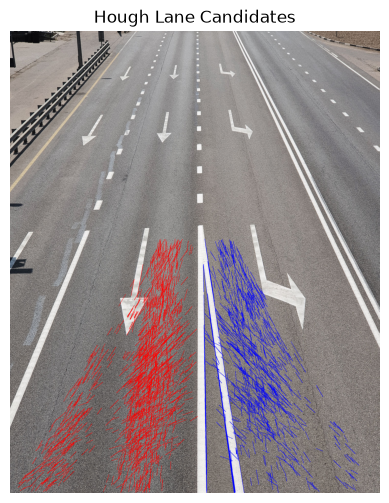


road_02.jpg
Left candidate segments: 0
Right candidate segments: 395


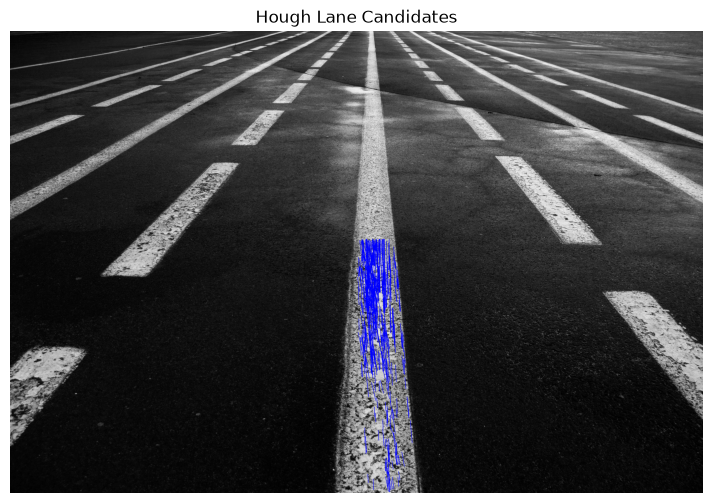


road_03.jpg
Left candidate segments: 0
Right candidate segments: 0


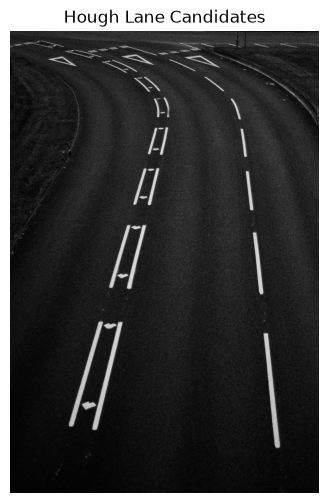

In [36]:
#30
for image_path in image_paths:
    diagnose_lane_candidates(image_path)

road_02.jpg
Raw Hough segments: 982


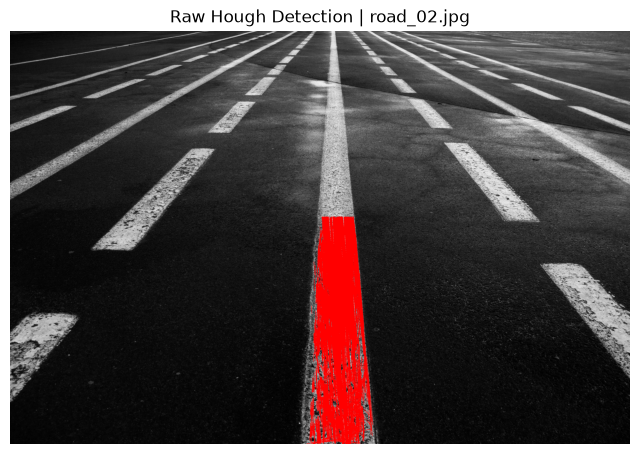

In [ ]:
# 31-D3
# Raw Hough detection check for road_02.jpg.
# Diagnostic only - does not modify the lane-detection pipeline.

# ---------------------------------------------------------
# Load road_02.jpg explicitly
# ---------------------------------------------------------

road_02_path = next(
    path for path in image_paths
    if path.name == "road_02.jpg"
)

image = cv2.imread(
    str(road_02_path)
)

if image is None:
    raise FileNotFoundError(
        f"Could not load image: {road_02_path}"
    )

image_rgb = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2RGB
)

height, width = image.shape[:2]

# ---------------------------------------------------------
# Grayscale and blur
# ---------------------------------------------------------

gray = cv2.cvtColor(
    image_rgb,
    cv2.COLOR_RGB2GRAY
)

blurred = cv2.GaussianBlur(
    gray,
    (5, 5),
    0
)

# ---------------------------------------------------------
# Canny edge detection
# ---------------------------------------------------------

edges = cv2.Canny(
    blurred,
    50,
    150
)

# ---------------------------------------------------------
# Region of interest
# ---------------------------------------------------------

roi_vertices = np.array([
    (0, height),
    (width, height),
    (int(width * 0.60), int(height * 0.45)),
    (int(width * 0.40), int(height * 0.45))
], dtype=np.int32)

mask = np.zeros_like(edges)

cv2.fillPoly(
    mask,
    [roi_vertices],
    255
)

# ---------------------------------------------------------
# Bright-pixel filtering
# ---------------------------------------------------------

white_mask = cv2.inRange(
    gray,
    180,
    255
)

roi_white_mask = cv2.bitwise_and(
    white_mask,
    mask
)

# ---------------------------------------------------------
# Raw Hough line detection
# ---------------------------------------------------------

lines = cv2.HoughLinesP(
    roi_white_mask,
    rho=1,
    theta=np.pi / 180,
    threshold=50,
    minLineLength=50,
    maxLineGap=30
)

# ---------------------------------------------------------
# Count detected Hough segments
# ---------------------------------------------------------

if lines is None:
    print("road_02.jpg")
    print("Raw Hough segments: 0")

else:
    print("road_02.jpg")
    print(
        f"Raw Hough segments: {len(lines)}"
    )

# ---------------------------------------------------------
# Visualize raw Hough segments
# ---------------------------------------------------------

visualization = image_rgb.copy()

if lines is not None:

    for line in lines:

        x1, y1, x2, y2 = line

        cv2.line(
            visualization,
            (x1, y1),
            (x2, y2),
            (255, 0, 0),
            2
        )

plt.figure(figsize=(8, 6))
plt.imshow(visualization)
plt.axis("off")
plt.title("Raw Hough Detection | road_02.jpg")
plt.show()

road_02.jpg
Raw Hough segments: 982
Classified left candidates: 4
Classified right candidates: 352


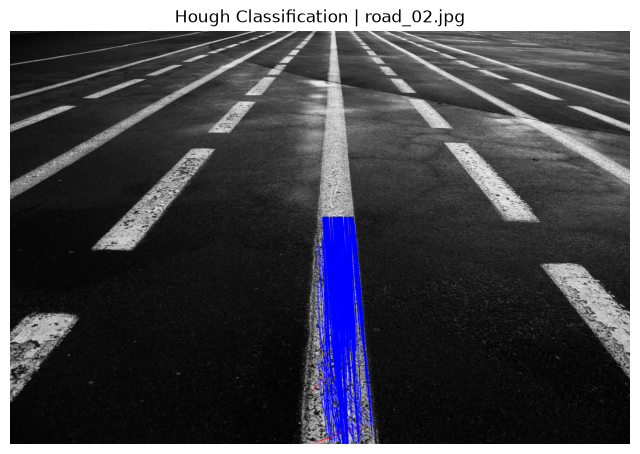

In [48]:
# 32 - D3
# Diagnose Hough left/right classification on road_02.jpg.
# Diagnostic only - does not modify the main detector.

# ---------------------------------------------------------
# Load road_02.jpg explicitly
# ---------------------------------------------------------

road_02_path = next(
    path for path in image_paths
    if path.name == "road_02.jpg"
)

image = cv2.imread(
    str(road_02_path)
)

if image is None:
    raise FileNotFoundError(
        f"Could not load image: {road_02_path}"
    )

image_rgb = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2RGB
)

height, width = image.shape[:2]

# ---------------------------------------------------------
# Pre-processing
# ---------------------------------------------------------

gray = cv2.cvtColor(
    image_rgb,
    cv2.COLOR_RGB2GRAY
)

blurred = cv2.GaussianBlur(
    gray,
    (5, 5),
    0
)

edges = cv2.Canny(
    blurred,
    50,
    150
)

# ---------------------------------------------------------
# Region of interest
# ---------------------------------------------------------

roi_vertices = np.array([
    (0, height),
    (width, height),
    (int(width * 0.60), int(height * 0.45)),
    (int(width * 0.40), int(height * 0.45))
], dtype=np.int32)

mask = np.zeros_like(edges)

cv2.fillPoly(
    mask,
    [roi_vertices],
    255
)

# ---------------------------------------------------------
# Bright-pixel filtering
# ---------------------------------------------------------

white_mask = cv2.inRange(
    gray,
    180,
    255
)

roi_white_mask = cv2.bitwise_and(
    white_mask,
    mask
)

# ---------------------------------------------------------
# Hough line detection
# ---------------------------------------------------------

lines = cv2.HoughLinesP(
    roi_white_mask,
    rho=1,
    theta=np.pi / 180,
    threshold=50,
    minLineLength=50,
    maxLineGap=30
)

# ---------------------------------------------------------
# Separate left and right candidates
# ---------------------------------------------------------

left_lines = []
right_lines = []

if lines is not None:

    # Make sure every Hough result is represented
    # as [x1, y1, x2, y2].
    line_segments = lines.reshape(-1, 4)

    for x1, y1, x2, y2 in line_segments:

        # Reorder the endpoints so that (x1, y1)
        # is the lower point in the image.
        if y1 < y2:
            x1, x2 = x2, x1
            y1, y2 = y2, y1

        # Ignore almost-vertical segments.
        if abs(x2 - x1) < 20:
            continue

        # Calculate the line slope.
        slope = (
            (y2 - y1)
            / (x2 - x1)
        )

        # Ignore nearly horizontal segments.
        if abs(slope) < 0.3:
            continue

        # Classify using the lower endpoint.
        if (
            x1 < width * 0.5
            and slope < 0
        ):
            left_lines.append(
                (x1, y1, x2, y2)
            )

        elif (
            x1 > width * 0.5
            and slope > 0
        ):
            right_lines.append(
                (x1, y1, x2, y2)
            )

# ---------------------------------------------------------
# Print classification results
# ---------------------------------------------------------

print("road_02.jpg")

print(
    f"Raw Hough segments: "
    f"{0 if lines is None else len(lines)}"
)

print(
    f"Classified left candidates: "
    f"{len(left_lines)}"
)

print(
    f"Classified right candidates: "
    f"{len(right_lines)}"
)

# ---------------------------------------------------------
# Visualize classified candidates
# ---------------------------------------------------------

visualization = image_rgb.copy()

# Left candidates = red.
for x1, y1, x2, y2 in left_lines:

    cv2.line(
        visualization,
        (x1, y1),
        (x2, y2),
        (255, 0, 0),
        2
    )

# Right candidates = blue.
for x1, y1, x2, y2 in right_lines:

    cv2.line(
        visualization,
        (x1, y1),
        (x2, y2),
        (0, 0, 255),
        2
    )

plt.figure(figsize=(8, 6))
plt.imshow(visualization)
plt.axis("off")
plt.title(
    "Hough Classification | road_02.jpg"
)
plt.show()

In [49]:
# 33 - D3
# Inspect Hough segment geometry for road_02.jpg.
# Diagnostic only - does not modify the main detector.

# ---------------------------------------------------------
# Inspect the classified candidates
# ---------------------------------------------------------

print("road_02.jpg")
print()

print(
    f"Left candidates: {len(left_lines)}"
)

print(
    f"Right candidates: {len(right_lines)}"
)

print()
print("First left-candidate segments:")

for line in left_lines[:10]:
    x1, y1, x2, y2 = line

    slope = (
        (y2 - y1)
        / (x2 - x1)
    )

    print(
        f"points=({x1}, {y1}) -> "
        f"({x2}, {y2}), "
        f"slope={slope:.3f}"
    )

print()
print("First right-candidate segments:")

for line in right_lines[:10]:
    x1, y1, x2, y2 = line

    slope = (
        (y2 - y1)
        / (x2 - x1)
    )

    print(
        f"points=({x1}, {y1}) -> "
        f"({x2}, {y2}), "
        f"slope={slope:.3f}"
    )

road_02.jpg

Left candidates: 4
Right candidates: 352

First left-candidate segments:
points=(2067, 2737) -> (2341, 2631), slope=-0.387
points=(2022, 2756) -> (2360, 2640), slope=-0.343
points=(2015, 2410) -> (2294, 2121), slope=-1.036
points=(2065, 2740) -> (2328, 2649), slope=-0.346

First right-candidate segments:
points=(2273, 2338) -> (2119, 1243), slope=7.110
points=(2325, 2755) -> (2293, 2395), slope=11.250
points=(2239, 2759) -> (2107, 1242), slope=11.492
points=(2241, 2273) -> (2187, 1243), slope=19.074
points=(2289, 2674) -> (2246, 2319), slope=8.256
points=(2225, 2517) -> (2113, 1242), slope=11.384
points=(2168, 2070) -> (2113, 1438), slope=11.491
points=(2192, 1964) -> (2116, 1242), slope=9.500
points=(2250, 2382) -> (2230, 1243), slope=56.950
points=(2237, 2755) -> (2105, 1243), slope=11.455


In [50]:
# 34-D3
# Inspect image geometry and candidate positions for road_02.jpg.
# Diagnostic only - does not modify the main detector.

print("road_02.jpg")
print()

print(f"Image width: {width}")
print(f"Image height: {height}")
print(f"Image centre x: {width / 2}")

print()

print("Left candidates:")
for line in left_lines:

    x1, y1, x2, y2 = line

    print(
        f"lower x = {x1}, "
        f"upper x = {x2}"
    )

print()

print("Right candidates:")
for line in right_lines[:10]:

    x1, y1, x2, y2 = line

    print(
        f"lower x = {x1}, "
        f"upper x = {x2}"
    )

road_02.jpg

Image width: 4140
Image height: 2760
Image centre x: 2070.0

Left candidates:
lower x = 2067, upper x = 2341
lower x = 2022, upper x = 2360
lower x = 2015, upper x = 2294
lower x = 2065, upper x = 2328

Right candidates:
lower x = 2273, upper x = 2119
lower x = 2325, upper x = 2293
lower x = 2239, upper x = 2107
lower x = 2241, upper x = 2187
lower x = 2289, upper x = 2246
lower x = 2225, upper x = 2113
lower x = 2168, upper x = 2113
lower x = 2192, upper x = 2116
lower x = 2250, upper x = 2230
lower x = 2237, upper x = 2105


In [51]:
# 35-D3
# Count raw Hough segments by position and slope.
# Diagnostic only - does not modify the main detector.

# ---------------------------------------------------------
# Classify raw Hough geometry into four groups
# ---------------------------------------------------------

left_negative = 0
left_positive = 0
right_negative = 0
right_positive = 0

if lines is not None:

    line_segments = lines.reshape(-1, 4)

    for x1, y1, x2, y2 in line_segments:

        # Reorder endpoints so that x1, y1
        # represents the lower point in the image.
        if y1 < y2:
            x1, x2 = x2, x1
            y1, y2 = y2, y1

        if abs(x2 - x1) < 20:
            continue

        slope = (
            (y2 - y1)
            / (x2 - x1)
        )

        if abs(slope) < 0.3:
            continue

        if x1 < width * 0.5:

            if slope < 0:
                left_negative += 1
            else:
                left_positive += 1

        else:

            if slope < 0:
                right_negative += 1
            else:
                right_positive += 1


# ---------------------------------------------------------
# Print the results
# ---------------------------------------------------------

print("road_02.jpg")
print()

print(
    f"Left of image centre + negative slope: "
    f"{left_negative}"
)

print(
    f"Left of image centre + positive slope: "
    f"{left_positive}"
)

print(
    f"Right of image centre + negative slope: "
    f"{right_negative}"
)

print(
    f"Right of image centre + positive slope: "
    f"{right_positive}"
)

road_02.jpg

Left of image centre + negative slope: 4
Left of image centre + positive slope: 1
Right of image centre + negative slope: 38
Right of image centre + positive slope: 353


In [52]:
# 36-D3
# Compare different brightness thresholds for road_02.jpg.
# Diagnostic only - does not modify the main detector.

thresholds = [140, 160, 180, 200]

print("road_02.jpg")
print()

for threshold in thresholds:

    test_white_mask = cv2.inRange(
        gray,
        threshold,
        255
    )

    test_roi_white_mask = cv2.bitwise_and(
        test_white_mask,
        mask
    )

    test_lines = cv2.HoughLinesP(
        test_roi_white_mask,
        rho=1,
        theta=np.pi / 180,
        threshold=50,
        minLineLength=50,
        maxLineGap=30
    )

    if test_lines is None:

        count = 0

    else:

        count = len(test_lines)

    print(
        f"Brightness threshold {threshold}: "
        f"{count} Hough segments"
    )

road_02.jpg

Brightness threshold 140: 635 Hough segments
Brightness threshold 160: 619 Hough segments
Brightness threshold 180: 982 Hough segments
Brightness threshold 200: 1103 Hough segments


In [53]:
# 37-D3
# Compare left/right Hough classification at different
# brightness thresholds for road_02.jpg.
# Diagnostic only - does not modify the main detector.

thresholds = [160, 180, 200]

print("road_02.jpg")
print()

for threshold in thresholds:

    test_white_mask = cv2.inRange(
        gray,
        threshold,
        255
    )

    test_roi_white_mask = cv2.bitwise_and(
        test_white_mask,
        mask
    )

    test_lines = cv2.HoughLinesP(
        test_roi_white_mask,
        rho=1,
        theta=np.pi / 180,
        threshold=50,
        minLineLength=50,
        maxLineGap=30
    )

    left_count = 0
    right_count = 0

    if test_lines is not None:

        test_segments = test_lines.reshape(-1, 4)

        for x1, y1, x2, y2 in test_segments:

            # Make (x1, y1) the lower endpoint.
            if y1 < y2:
                x1, x2 = x2, x1
                y1, y2 = y2, y1

            if abs(x2 - x1) < 20:
                continue

            slope = (
                (y2 - y1)
                / (x2 - x1)
            )

            if abs(slope) < 0.3:
                continue

            if (
                x1 < width * 0.5
                and slope < 0
            ):
                left_count += 1

            elif (
                x1 > width * 0.5
                and slope > 0
            ):
                right_count += 1

    print(
        f"Threshold {threshold}: "
        f"left = {left_count}, "
        f"right = {right_count}"
    )

road_02.jpg

Threshold 160: left = 0, right = 247
Threshold 180: left = 4, right = 352
Threshold 200: left = 3, right = 127
